
# Buy Fee Model V7 — Causal Readiness & Grouped Validation

## Objective

This notebook answers a different question from the earlier ML notebooks:

> **Does the cleaned historical data contain a stable, decision-useful relationship between Buy Fee increases and Volume, Conversion, and Buy Fee RPU?**

The notebook does **not** assume that every observed post-change movement was caused by Buy Fee.

It performs five layers of validation:

1. **Event-study diagnostics**  
   What happens from 12 weeks before through 12 weeks after fee changes?

2. **Pre-trend checks**  
   Were Volume / Conversion / RPU already moving before the fee change?

3. **Fixed-effects baselines**  
   Estimate the relationship between fee changes and outcomes while controlling for:
   - Location
   - Lane
   - Price tier
   - Corporate change date
   - Prior outcome levels/trends
   - Vehicle mix

4. **Grouped-by-Corporate_Change_ID validation**  
   Entire corporate fee-change dates are held out together so the same pricing action cannot appear in both train and test.

5. **Readiness assessment**
   Each target receives:
   - **GO**
   - **IMPROVE DATA**
   - **RESEARCH ONLY**

## Important interpretation

A **GO** does not mean causality is proven or the model is production-ready without governance.  
It means the target has enough historical support and out-of-group stability to proceed to the next modeling stage.

A **RESEARCH ONLY** result means the relationship is too unstable for pricing recommendations.

An **IMPROVE DATA** result means the limiting factor is primarily coverage / sample support rather than model specification.


In [3]:
!python -m pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.3 MB 5.5 MB/s eta 0:00:02
   ------------------------------ --------- 8.7/11.3 MB 33.0 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 36.0 MB/s  0:00:00

   ---------------------------------------- 0/5 [wrapt]
   ---------------------------------------- 0/5 [wrapt]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulai

In [4]:

from pathlib import Path
import pandas as pd
import numpy as np
import warnings
import math

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    r2_score
)

import statsmodels.formula.api as smf

# ============================================================
# USER CONFIGURATION
# ============================================================

DATA_FOLDER = Path(
    r"C:\Users\ViditSheth\OneDrive - America's Auto Auction\Finance - Documents\FP&A\Data Analytics\Development\Vidit_Sanbox\Buy Fee Model Phase 2\Rough Area\Volume Attirtion"
)

V61_DIR = DATA_FOLDER / "buy_fee_model_dataset_v6_1"

WEEKLY_FILE = V61_DIR / "04_WEEKLY_MODEL_PANEL_V6_1.csv"
EVENTS_FILE = V61_DIR / "05_CLEAN_FEE_CHANGE_EVENTS_V6_1.csv"
PRIMARY_FILE = V61_DIR / "08_MODEL_READY_PRIMARY_V6_1.csv"
STRICT_FILE = V61_DIR / "09_MODEL_READY_STRICT_V6_1.csv"
RPU_FILE = V61_DIR / "10_MODEL_READY_RPU_V6_1.csv"

OUTPUT_DIR = DATA_FOLDER / "buy_fee_model_v7_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

EVENT_STUDY_WEEKS = 12

SCENARIOS = [10, 15, 20, 25, 30]

RANDOM_STATE = 42

# Readiness gates - intentionally conservative and transparent
MIN_UNIQUE_CHANGE_DATES_GO = 12
MIN_UNIQUE_LOCATIONS_GO = 10
MIN_GROUPED_R2_GO = 0.10
MIN_DIRECTION_GO = 0.60
MIN_SIGN_STABILITY_GO = 0.70

MIN_UNIQUE_CHANGE_DATES_IMPROVE = 6
MIN_UNIQUE_LOCATIONS_IMPROVE = 5

print("=" * 80)
print("V7 INPUT CHECK")
print("=" * 80)

for p in [
    WEEKLY_FILE,
    EVENTS_FILE,
    PRIMARY_FILE,
    STRICT_FILE,
    RPU_FILE
]:
    print(p.name, "->", p.exists())

missing = [
    p for p in [
        WEEKLY_FILE,
        EVENTS_FILE,
        PRIMARY_FILE,
        STRICT_FILE,
        RPU_FILE
    ]
    if not p.exists()
]

if missing:
    raise FileNotFoundError(
        "Missing required V6.1 output(s):\n"
        + "\n".join(str(x) for x in missing)
    )


V7 INPUT CHECK
04_WEEKLY_MODEL_PANEL_V6_1.csv -> True
05_CLEAN_FEE_CHANGE_EVENTS_V6_1.csv -> True
08_MODEL_READY_PRIMARY_V6_1.csv -> True
09_MODEL_READY_STRICT_V6_1.csv -> True
10_MODEL_READY_RPU_V6_1.csv -> True


## 1. Load V6.1 outputs

In [5]:

weekly = pd.read_csv(
    WEEKLY_FILE,
    parse_dates=["Week_Start"],
    low_memory=False
)

events = pd.read_csv(
    EVENTS_FILE,
    parse_dates=["BUYFEE_CHANGE_DATE", "Prev_Change_Date", "Next_Change_Date"],
    low_memory=False
)

primary = pd.read_csv(
    PRIMARY_FILE,
    parse_dates=["BUYFEE_CHANGE_DATE", "Event_Week"],
    low_memory=False
)

strict = pd.read_csv(
    STRICT_FILE,
    parse_dates=["BUYFEE_CHANGE_DATE", "Event_Week"],
    low_memory=False
)

rpu = pd.read_csv(
    RPU_FILE,
    parse_dates=["BUYFEE_CHANGE_DATE", "Event_Week"],
    low_memory=False
)

print("Weekly rows :", f"{len(weekly):,}")
print("All events  :", f"{len(events):,}")
print("Primary     :", f"{len(primary):,}")
print("Strict      :", f"{len(strict):,}")
print("RPU ready   :", f"{len(rpu):,}")

print("\nPrimary unique locations:", primary["VRLOCATION"].nunique())
print("Primary unique change dates:", primary["Corporate_Change_ID"].nunique())

print("\nRPU unique locations:", rpu["VRLOCATION"].nunique())
print("RPU unique change dates:", rpu["Corporate_Change_ID"].nunique())


Weekly rows : 1,689,856
All events  : 9,251
Primary     : 2,142
Strict      : 1,843
RPU ready   : 504

Primary unique locations: 35
Primary unique change dates: 39

RPU unique locations: 26
RPU unique change dates: 34



## 2. Event-study panel: week -12 to +12

The event-study panel uses the robust weekly data.

For each fee-change segment we calculate outcome values relative to its own pre-period baseline.

The event week (`0`) is excluded from causal interpretation because the fee may have changed partway through the week.


In [6]:

panel_lookup = {
    key: grp.sort_values("Week_Start").copy()
    for key, grp in weekly.groupby(
        ["VRLOCATION", "LANE", "price_tier"],
        sort=False
    )
}

event_study_rows = []

for i, e in strict.iterrows():

    key = (
        e["VRLOCATION"],
        e["LANE"],
        e["price_tier"]
    )

    seg = panel_lookup.get(key)

    if seg is None or seg.empty:
        continue

    event_week = pd.Timestamp(e["Event_Week"])

    pre_baseline = seg[
        seg["Week_Start"].between(
            event_week - pd.Timedelta(weeks=8),
            event_week - pd.Timedelta(weeks=1)
        )
    ]

    if pre_baseline.empty:
        continue

    base_registered = pre_baseline["Registered_Units"].mean()
    base_sold = pre_baseline["Sold_Units"].mean()
    base_conversion = (
        pre_baseline["Sold_Units"].sum()
        / pre_baseline["Registered_Units"].sum()
        if pre_baseline["Registered_Units"].sum() > 0
        else np.nan
    )

    base_rpu = (
        pre_baseline["BuyFee_Revenue"].sum()
        / pre_baseline["Sold_Units"].sum()
        if pre_baseline["Sold_Units"].sum() > 0
        else np.nan
    )

    for rel_week in range(-EVENT_STUDY_WEEKS, EVENT_STUDY_WEEKS + 1):

        target_week = (
            event_week
            + pd.Timedelta(weeks=rel_week)
        )

        obs = seg[
            seg["Week_Start"].eq(target_week)
        ]

        if obs.empty:
            continue

        registered = obs["Registered_Units"].sum()
        sold = obs["Sold_Units"].sum()

        conversion = (
            sold / registered
            if registered > 0
            else np.nan
        )

        rpu_week = (
            obs["BuyFee_Revenue"].sum() / sold
            if sold > 0
            else np.nan
        )

        volume_index = (
            sold / base_sold - 1
            if pd.notna(base_sold) and base_sold > 0
            else np.nan
        )

        registered_index = (
            registered / base_registered - 1
            if pd.notna(base_registered) and base_registered > 0
            else np.nan
        )

        conversion_delta_pp = (
            (conversion - base_conversion) * 100
            if pd.notna(conversion)
            and pd.notna(base_conversion)
            else np.nan
        )

        rpu_delta_dollar = (
            rpu_week - base_rpu
            if pd.notna(rpu_week)
            and pd.notna(base_rpu)
            else np.nan
        )

        event_study_rows.append({
            "Segment_Change_ID": e["Segment_Change_ID"],
            "Corporate_Change_ID": e["Corporate_Change_ID"],
            "VRLOCATION": e["VRLOCATION"],
            "LANE": e["LANE"],
            "price_tier": e["price_tier"],
            "BUYFEE_CHANGE_AMOUNT": e["BUYFEE_CHANGE_AMOUNT"],
            "Relative_Week": rel_week,
            "Registered_Units": registered,
            "Sold_Units": sold,
            "Conversion": conversion,
            "BuyFee_RPU": rpu_week,
            "Volume_vs_Pre8W": volume_index,
            "Registered_vs_Pre8W": registered_index,
            "Conversion_Change_pp_vs_Pre8W": conversion_delta_pp,
            "RPU_Change_Dollar_vs_Pre8W": rpu_delta_dollar,
        })

event_study = pd.DataFrame(event_study_rows)

event_study.to_csv(
    OUTPUT_DIR / "01_EVENT_STUDY_PANEL.csv",
    index=False
)

print("Event-study rows:", f"{len(event_study):,}")
print("Strict events represented:", event_study["Segment_Change_ID"].nunique())


Event-study rows: 44,322
Strict events represented: 1843


## 3. Aggregate event-study curves and pre-trend diagnostics

In [7]:

event_curve = (
    event_study.groupby("Relative_Week")
    .agg(
        Events=("Segment_Change_ID", "nunique"),
        Avg_Volume_vs_Pre8W=("Volume_vs_Pre8W", "mean"),
        Median_Volume_vs_Pre8W=("Volume_vs_Pre8W", "median"),
        Avg_Conversion_Change_pp=("Conversion_Change_pp_vs_Pre8W", "mean"),
        Median_Conversion_Change_pp=("Conversion_Change_pp_vs_Pre8W", "median"),
        Avg_RPU_Change_Dollar=("RPU_Change_Dollar_vs_Pre8W", "mean"),
        Median_RPU_Change_Dollar=("RPU_Change_Dollar_vs_Pre8W", "median"),
    )
    .reset_index()
)

event_curve.to_csv(
    OUTPUT_DIR / "02_EVENT_STUDY_CURVES.csv",
    index=False
)

display(event_curve)

# Pre-trend slopes using weeks -12 through -2
pre_curve = event_curve[
    event_curve["Relative_Week"].between(-12, -2)
].copy()

def slope_from_curve(df, y_col):
    d = df[["Relative_Week", y_col]].dropna()

    if len(d) < 3:
        return np.nan

    return np.polyfit(
        d["Relative_Week"],
        d[y_col],
        1
    )[0]

pretrend_summary = pd.DataFrame([
    {
        "Target": "Volume",
        "Pretrend_Slope_Per_Week": slope_from_curve(
            pre_curve,
            "Median_Volume_vs_Pre8W"
        )
    },
    {
        "Target": "Conversion",
        "Pretrend_Slope_Per_Week": slope_from_curve(
            pre_curve,
            "Median_Conversion_Change_pp"
        )
    },
    {
        "Target": "RPU",
        "Pretrend_Slope_Per_Week": slope_from_curve(
            pre_curve,
            "Median_RPU_Change_Dollar"
        )
    },
])

pretrend_summary.to_csv(
    OUTPUT_DIR / "03_PRETREND_SUMMARY.csv",
    index=False
)

display(pretrend_summary)


,Relative_Week,Events,Avg_Volume_vs_Pre8W,Median_Volume_vs_Pre8W,Avg_Conversion_Change_pp,Median_Conversion_Change_pp,Avg_RPU_Change_Dollar,Median_RPU_Change_Dollar
0,-12,1714,0.012999,-0.102745,1.886960,2.055661,1.223701,8.455882
1,-11,1744,0.087209,0.000000,1.531449,2.695218,-0.485019,8.269916
2,-10,1739,0.005659,-0.111111,-0.213905,0.444444,-4.462108,1.731602
3,-9,1705,0.012502,-0.098592,-0.378248,0.775194,-2.495692,6.836735
4,-8,1761,0.021482,-0.050847,0.101017,1.136364,2.750446,7.741477
5,-7,1771,0.033728,-0.030303,0.427465,1.794258,-5.543018,0.000000
6,-6,1820,-0.055899,-0.111111,-0.769733,0.000000,1.561926,7.234075
7,-5,1809,0.013726,-0.050847,-0.375889,0.980392,2.465856,7.854406
8,-4,1818,-0.029254,-0.076923,-1.181265,0.000000,-0.707369,7.229322
9,-3,1827,0.004994,-0.058824,-1.162896,0.000000,-2.110944,3.419913


,Target,Pretrend_Slope_Per_Week
0,Volume,0.000466
1,Conversion,-0.152040
2,RPU,-0.187872


## 4. Event-study charts

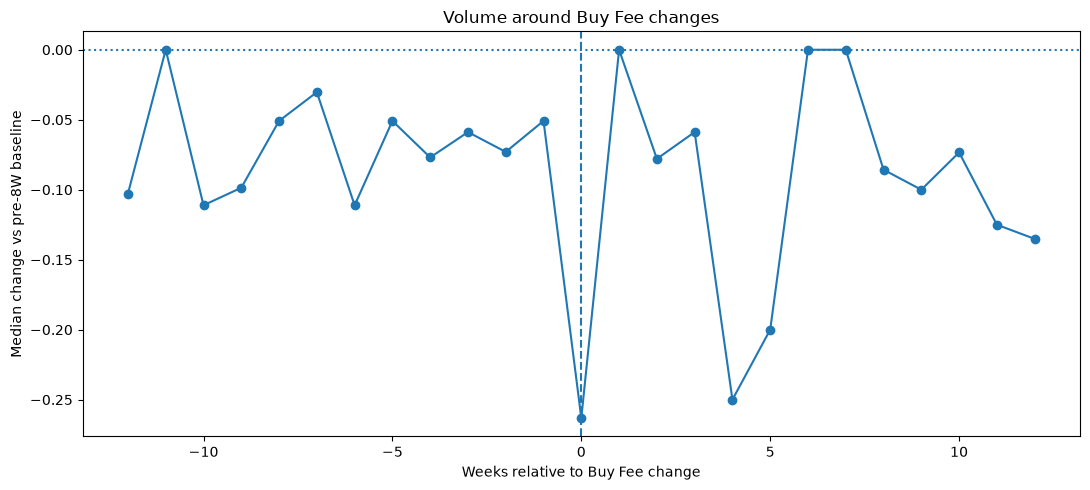

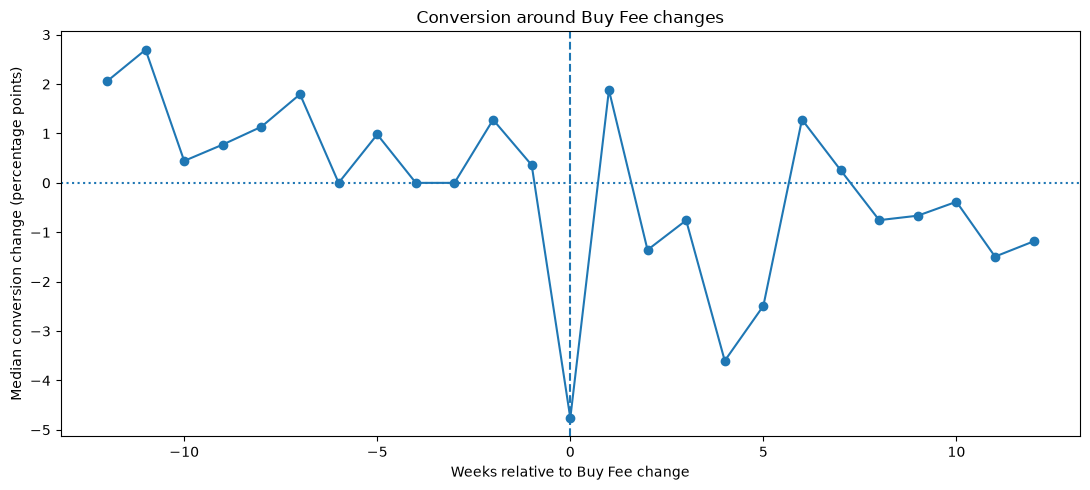

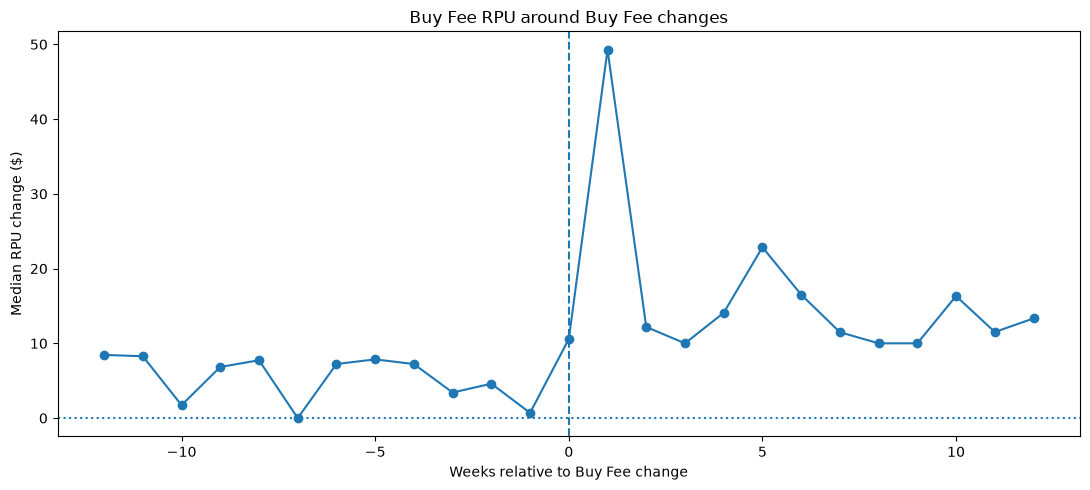

In [8]:

def save_event_plot(y_col, title, ylabel, filename):
    d = event_curve[
        event_curve["Relative_Week"].between(-12, 12)
    ]

    plt.figure(figsize=(11, 5))
    plt.plot(
        d["Relative_Week"],
        d[y_col],
        marker="o"
    )
    plt.axvline(0, linestyle="--")
    plt.axhline(0, linestyle=":")
    plt.title(title)
    plt.xlabel("Weeks relative to Buy Fee change")
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

save_event_plot(
    "Median_Volume_vs_Pre8W",
    "Volume around Buy Fee changes",
    "Median change vs pre-8W baseline",
    "04_EVENT_STUDY_VOLUME.png"
)

save_event_plot(
    "Median_Conversion_Change_pp",
    "Conversion around Buy Fee changes",
    "Median conversion change (percentage points)",
    "05_EVENT_STUDY_CONVERSION.png"
)

save_event_plot(
    "Median_RPU_Change_Dollar",
    "Buy Fee RPU around Buy Fee changes",
    "Median RPU change ($)",
    "06_EVENT_STUDY_RPU.png"
)



## 5. Fixed-effects baselines

These models are designed to be **interpretable baselines**, not final production models.

We estimate outcome changes as a function of:

- Buy Fee change dollars
- Buy Fee change percentage
- Pre-period level
- Pre-period trend
- Sale-price mix
- Mileage
- Vehicle age
- Location fixed effects
- Lane fixed effects
- Price-tier fixed effects
- Corporate change-date fixed effects

`Corporate_Change_ID` fixed effects absorb common conditions specific to each company-wide fee-change date.

Because Location, Lane, Tier, and Corporate Change Date can create many dummy variables, the notebook first removes unusable/missing values and then fits OLS with clustered standard errors by Corporate Change ID when possible.


In [9]:

def prepare_fixed_effects_df(df, target_col):
    d = df.copy()

    numeric_cols = [
        "BUYFEE_CHANGE_AMOUNT",
        "FEE_CHANGE_PCT",
        "pre_8w_registered",
        "pre_8w_sold",
        "pre_8w_conversion",
        "pre_8w_buyfee_rpu",
        "pre_8w_volume_trend",
        "pre_8w_conversion_trend",
        "pre_8w_avg_saleamt",
        "pre_8w_avg_age",
        "pre_8w_avg_mileage",
        "pre_8w_avg_condition",
        "pre_8w_avg_high_bid",
        "pre_8w_avg_floor",
        target_col
    ]

    for c in numeric_cols:
        if c in d.columns:
            d[c] = pd.to_numeric(
                d[c],
                errors="coerce"
            )

    return d

def fit_fe_model(df, target_col, target_name):

    d = prepare_fixed_effects_df(
        df,
        target_col
    )

    candidate_controls = [
        "BUYFEE_CHANGE_AMOUNT",
        "FEE_CHANGE_PCT",
        "pre_8w_registered",
        "pre_8w_sold",
        "pre_8w_conversion",
        "pre_8w_buyfee_rpu",
        "pre_8w_volume_trend",
        "pre_8w_conversion_trend",
        "pre_8w_avg_saleamt",
        "pre_8w_avg_age",
        "pre_8w_avg_mileage",
        "pre_8w_avg_condition",
        "pre_8w_avg_high_bid",
        "pre_8w_avg_floor",
    ]

    controls = [
        c for c in candidate_controls
        if c in d.columns
        and d[c].notna().sum() >= max(20, int(len(d) * 0.25))
    ]

    keep_cols = [
        target_col,
        "VRLOCATION",
        "LANE",
        "price_tier",
        "Corporate_Change_ID"
    ] + controls

    d = d[
        list(dict.fromkeys(keep_cols))
    ].copy()

    # Fill numeric control missing values with median
    for c in controls:
        d[c] = d[c].fillna(
            d[c].median()
        )

    d = d.dropna(
        subset=[
            target_col,
            "VRLOCATION",
            "LANE",
            "price_tier",
            "Corporate_Change_ID",
            "BUYFEE_CHANGE_AMOUNT"
        ]
    ).copy()

    # Keep FE formula reasonably stable
    formula = (
        f"{target_col} ~ "
        + " + ".join(controls)
        + " + C(VRLOCATION)"
        + " + C(LANE)"
        + " + C(price_tier)"
        + " + C(Corporate_Change_ID)"
    )

    try:
        model = smf.ols(
            formula=formula,
            data=d
        ).fit(
            cov_type="cluster",
            cov_kwds={
                "groups": d["Corporate_Change_ID"]
            }
        )

        clustered = True

    except Exception as exc:
        print(
            f"{target_name}: clustered SE failed, "
            "falling back to HC3.",
            exc
        )

        model = smf.ols(
            formula=formula,
            data=d
        ).fit(
            cov_type="HC3"
        )

        clustered = False

    fee_coef = model.params.get(
        "BUYFEE_CHANGE_AMOUNT",
        np.nan
    )

    fee_pvalue = model.pvalues.get(
        "BUYFEE_CHANGE_AMOUNT",
        np.nan
    )

    fee_ci = (
        model.conf_int().loc["BUYFEE_CHANGE_AMOUNT"].tolist()
        if "BUYFEE_CHANGE_AMOUNT" in model.params.index
        else [np.nan, np.nan]
    )

    result = {
        "Target": target_name,
        "Rows": len(d),
        "Locations": d["VRLOCATION"].nunique(),
        "Corporate_Change_Dates": d["Corporate_Change_ID"].nunique(),
        "R2": model.rsquared,
        "Adj_R2": model.rsquared_adj,
        "Fee_Change_Dollar_Coefficient": fee_coef,
        "Fee_Change_PValue": fee_pvalue,
        "Fee_CI_Low": fee_ci[0],
        "Fee_CI_High": fee_ci[1],
        "Clustered_SE": clustered,
        "Controls_Used": " | ".join(controls)
    }

    return model, result, d

fe_models = {}
fe_results = []

for name, df, target in [
    (
        "Volume",
        strict,
        "volume_change_pct_8w"
    ),
    (
        "Conversion",
        strict,
        "conversion_change_pp_8w"
    ),
    (
        "RPU",
        rpu,
        "rpu_dollar_change_8w"
    ),
]:

    model, result, used_df = fit_fe_model(
        df,
        target,
        name
    )

    fe_models[name] = {
        "model": model,
        "data": used_df,
        "target": target
    }

    fe_results.append(result)

fixed_effects_summary = pd.DataFrame(
    fe_results
)

fixed_effects_summary.to_csv(
    OUTPUT_DIR / "07_FIXED_EFFECTS_SUMMARY.csv",
    index=False
)

display(fixed_effects_summary)


C:\Users\ViditSheth\AppData\Local\Temp\ipykernel_26644\1735613134.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
C:\Users\ViditSheth\AppData\Local\Temp\ipykernel_26644\1735613134.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
C:\Users\ViditSheth\AppData\Local\Temp\ipykernel_26644\1735613134.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(


,Target,Rows,Locations,Corporate_Change_Dates,R2,Adj_R2,Fee_Change_Dollar_Coefficient,Fee_Change_PValue,Fee_CI_Low,Fee_CI_High,Clustered_SE,Controls_Used
0,Volume,1843,35,37,0.401018,0.326420,-0.000253,0.869854,-0.003281,0.002774,True,BUYFEE_CHANGE_AMOUNT | FEE_CHANGE_PCT | pre_8w...
1,Conversion,1843,35,37,0.430220,0.359258,-0.065369,0.185215,-0.162074,0.031336,True,BUYFEE_CHANGE_AMOUNT | FEE_CHANGE_PCT | pre_8w...
2,RPU,504,26,34,0.534719,0.357042,0.101310,0.390114,-0.129737,0.332358,True,BUYFEE_CHANGE_AMOUNT | FEE_CHANGE_PCT | pre_8w...



## 6. Grouped validation by Corporate Change ID

A random row split is **not allowed** here because many segment rows come from the same corporate pricing action.

This validation:

- Sorts Corporate Change IDs chronologically
- Builds expanding-window tests
- Holds out complete change dates
- Never allows the same Corporate Change ID in both train and test

The predictive model is a Ridge + Random Forest ensemble.  
The goal is not to prove the algorithm is best; the goal is to test whether the signal generalizes to unseen pricing actions.


In [10]:

def make_ohe():
    try:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    except TypeError:
        return OneHotEncoder(
            handle_unknown="ignore",
            sparse=True
        )

def build_pipeline(model, X):

    numeric = [
        c for c in X.columns
        if pd.api.types.is_numeric_dtype(X[c])
    ]

    categorical = [
        c for c in X.columns
        if c not in numeric
    ]

    num_pipe = Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scale",
            StandardScaler()
        )
    ])

    cat_pipe = Pipeline([
        (
            "impute",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "ohe",
            make_ohe()
        )
    ])

    prep = ColumnTransformer(
        [
            ("num", num_pipe, numeric),
            ("cat", cat_pipe, categorical)
        ],
        remainder="drop"
    )

    return Pipeline([
        ("prep", prep),
        ("model", model)
    ])

candidate_features = [
    "BUYFEE_CHANGE_AMOUNT",
    "FEE_CHANGE_PCT",
    "PREVIOUS_BUYFEE",
    "VRLOCATION",
    "LANE",
    "price_tier",

    "pre_8w_registered",
    "pre_8w_sold",
    "pre_8w_conversion",
    "pre_8w_buyfee_rpu",
    "pre_8w_buyfee_coverage",

    "pre_8w_avg_saleamt",
    "pre_8w_avg_age",
    "pre_8w_avg_mileage",
    "pre_8w_avg_condition",
    "pre_8w_avg_high_bid",
    "pre_8w_avg_floor",

    "pre_8w_volume_trend",
    "pre_8w_conversion_trend",
    "pre_8w_volume_cv",
    "pre_8w_conversion_cv",

    "Weeks_Since_Prior_Change",
    "Weeks_To_Next_Change",
]

def grouped_chronological_validation(
    df,
    target_col,
    target_name,
    min_train_groups=8,
    n_test_groups=3
):

    d = df.copy()

    d = d.dropna(
        subset=[
            target_col,
            "Corporate_Change_ID",
            "BUYFEE_CHANGE_DATE"
        ]
    ).copy()

    d["BUYFEE_CHANGE_DATE"] = pd.to_datetime(
        d["BUYFEE_CHANGE_DATE"],
        errors="coerce"
    )

    features = [
        c for c in candidate_features
        if c in d.columns
    ]

    group_dates = (
        d[
            [
                "Corporate_Change_ID",
                "BUYFEE_CHANGE_DATE"
            ]
        ]
        .drop_duplicates()
        .sort_values(
            "BUYFEE_CHANGE_DATE"
        )
        ["Corporate_Change_ID"]
        .tolist()
    )

    fold_rows = []
    prediction_parts = []

    if len(group_dates) < (
        min_train_groups
        + n_test_groups
    ):
        return (
            pd.DataFrame(),
            pd.DataFrame(),
            {
                "Target": target_name,
                "Status": "INSUFFICIENT_GROUPS"
            }
        )

    fold_num = 0

    train_end = min_train_groups

    while (
        train_end + n_test_groups
        <= len(group_dates)
    ):

        fold_num += 1

        train_groups = group_dates[
            :train_end
        ]

        test_groups = group_dates[
            train_end:
            train_end + n_test_groups
        ]

        train = d[
            d["Corporate_Change_ID"].isin(
                train_groups
            )
        ].copy()

        test = d[
            d["Corporate_Change_ID"].isin(
                test_groups
            )
        ].copy()

        if (
            len(train) < 50
            or len(test) < 10
        ):
            train_end += n_test_groups
            continue

        Xtr = train[features]
        ytr = train[target_col]

        Xte = test[features]
        yte = test[target_col]

        ridge = build_pipeline(
            Ridge(alpha=10.0),
            Xtr
        )

        rf = build_pipeline(
            RandomForestRegressor(
                n_estimators=300,
                min_samples_leaf=max(
                    3,
                    int(len(train) * 0.01)
                ),
                max_features="sqrt",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ),
            Xtr
        )

        ridge.fit(Xtr, ytr)
        rf.fit(Xtr, ytr)

        pred_ridge = ridge.predict(Xte)
        pred_rf = rf.predict(Xte)

        pred = (
            pred_ridge
            + pred_rf
        ) / 2

        mae = mean_absolute_error(
            yte,
            pred
        )

        naive_value = ytr.median()

        naive_pred = np.repeat(
            naive_value,
            len(yte)
        )

        naive_mae = mean_absolute_error(
            yte,
            naive_pred
        )

        r2 = (
            r2_score(yte, pred)
            if len(yte) > 1
            else np.nan
        )

        direction = np.mean(
            np.sign(pred)
            == np.sign(yte)
        )

        fold_rows.append({
            "Target": target_name,
            "Fold": fold_num,
            "Train_Groups": len(train_groups),
            "Test_Groups": len(test_groups),
            "Train_Rows": len(train),
            "Test_Rows": len(test),
            "Test_Group_IDs": " | ".join(
                map(str, test_groups)
            ),
            "MAE": mae,
            "Naive_MAE": naive_mae,
            "MAE_Improvement_vs_Naive": (
                1 - mae / naive_mae
                if naive_mae > 0
                else np.nan
            ),
            "R2": r2,
            "Direction_Accuracy": direction,
        })

        pp = test[
            [
                "Segment_Change_ID",
                "Corporate_Change_ID",
                "VRLOCATION",
                "LANE",
                "price_tier",
                "BUYFEE_CHANGE_AMOUNT",
                target_col
            ]
        ].copy()

        pp["Predicted"] = pred
        pp["Fold"] = fold_num
        pp["Target"] = target_name

        prediction_parts.append(pp)

        train_end += n_test_groups

    folds = pd.DataFrame(
        fold_rows
    )

    preds = (
        pd.concat(
            prediction_parts,
            ignore_index=True
        )
        if prediction_parts
        else pd.DataFrame()
    )

    if folds.empty:
        summary = {
            "Target": target_name,
            "Status": "NO_VALID_FOLDS"
        }

    else:
        summary = {
            "Target": target_name,
            "Status": "OK",
            "Folds": len(folds),
            "Median_R2": folds["R2"].median(),
            "Median_MAE": folds["MAE"].median(),
            "Median_Naive_MAE": folds["Naive_MAE"].median(),
            "Median_MAE_Improvement_vs_Naive": folds[
                "MAE_Improvement_vs_Naive"
            ].median(),
            "Median_Direction_Accuracy": folds[
                "Direction_Accuracy"
            ].median(),
            "Positive_R2_Fold_Share": (
                folds["R2"] > 0
            ).mean(),
            "Direction_Above_50_Fold_Share": (
                folds["Direction_Accuracy"] > 0.50
            ).mean(),
        }

    return folds, preds, summary

grouped_fold_parts = []
grouped_pred_parts = []
grouped_summaries = []

for name, df, target in [
    (
        "Volume",
        strict,
        "volume_change_pct_8w"
    ),
    (
        "Conversion",
        strict,
        "conversion_change_pp_8w"
    ),
    (
        "RPU",
        rpu,
        "rpu_dollar_change_8w"
    )
]:

    folds, preds, summary = (
        grouped_chronological_validation(
            df,
            target,
            name
        )
    )

    if not folds.empty:
        grouped_fold_parts.append(
            folds
        )

    if not preds.empty:
        grouped_pred_parts.append(
            preds
        )

    grouped_summaries.append(
        summary
    )

grouped_folds = (
    pd.concat(
        grouped_fold_parts,
        ignore_index=True
    )
    if grouped_fold_parts
    else pd.DataFrame()
)

grouped_predictions = (
    pd.concat(
        grouped_pred_parts,
        ignore_index=True
    )
    if grouped_pred_parts
    else pd.DataFrame()
)

grouped_summary = pd.DataFrame(
    grouped_summaries
)

grouped_folds.to_csv(
    OUTPUT_DIR / "08_GROUPED_VALIDATION_FOLDS.csv",
    index=False
)

grouped_predictions.to_csv(
    OUTPUT_DIR / "09_GROUPED_VALIDATION_PREDICTIONS.csv",
    index=False
)

grouped_summary.to_csv(
    OUTPUT_DIR / "10_GROUPED_VALIDATION_SUMMARY.csv",
    index=False
)

display(grouped_summary)


,Target,Status,Folds,Median_R2,Median_MAE,Median_Naive_MAE,Median_MAE_Improvement_vs_Naive,Median_Direction_Accuracy,Positive_R2_Fold_Share,Direction_Above_50_Fold_Share
0,Volume,OK,9,-0.071172,0.285270,0.283282,-0.045712,0.530612,0.333333,0.666667
1,Conversion,OK,9,0.087078,9.631015,9.683788,0.081485,0.663366,0.666667,0.777778
2,RPU,OK,8,0.287942,12.522471,14.926546,0.169458,0.817147,0.625000,1.000000


## 7. Fixed-effects sign stability across Corporate Change IDs

In [11]:

def leave_one_group_out_fee_coefficients(
    df,
    target_col,
    target_name
):

    d = prepare_fixed_effects_df(
        df,
        target_col
    )

    groups = (
        d["Corporate_Change_ID"]
        .dropna()
        .unique()
        .tolist()
    )

    rows = []

    for g in groups:

        train = d[
            d["Corporate_Change_ID"].ne(g)
        ].copy()

        if (
            len(train) < 100
            or train[
                "Corporate_Change_ID"
            ].nunique() < 5
        ):
            continue

        try:

            model, result, used = (
                fit_fe_model(
                    train,
                    target_col,
                    target_name
                )
            )

            rows.append({
                "Target": target_name,
                "Held_Out_Corporate_Change_ID": g,
                "Fee_Coefficient": result[
                    "Fee_Change_Dollar_Coefficient"
                ],
                "PValue": result[
                    "Fee_Change_PValue"
                ],
                "Rows": result["Rows"],
            })

        except Exception:
            continue

    return pd.DataFrame(rows)

loo_parts = []

for name, df, target in [
    (
        "Volume",
        strict,
        "volume_change_pct_8w"
    ),
    (
        "Conversion",
        strict,
        "conversion_change_pp_8w"
    ),
    (
        "RPU",
        rpu,
        "rpu_dollar_change_8w"
    )
]:

    temp = (
        leave_one_group_out_fee_coefficients(
            df,
            target,
            name
        )
    )

    if not temp.empty:
        loo_parts.append(temp)

loo_coefs = (
    pd.concat(
        loo_parts,
        ignore_index=True
    )
    if loo_parts
    else pd.DataFrame()
)

loo_coefs.to_csv(
    OUTPUT_DIR / "11_FEE_COEFFICIENT_STABILITY.csv",
    index=False
)

stability_rows = []

if not loo_coefs.empty:

    for target, g in loo_coefs.groupby("Target"):

        median_coef = g["Fee_Coefficient"].median()

        if median_coef == 0 or pd.isna(median_coef):
            sign_stability = np.nan
        else:
            sign_stability = (
                np.sign(g["Fee_Coefficient"])
                == np.sign(median_coef)
            ).mean()

        stability_rows.append({
            "Target": target,
            "LOO_Runs": len(g),
            "Median_Fee_Coefficient": median_coef,
            "Coefficient_Min": g["Fee_Coefficient"].min(),
            "Coefficient_Max": g["Fee_Coefficient"].max(),
            "Sign_Stability": sign_stability,
        })

coefficient_stability = pd.DataFrame(
    stability_rows
)

coefficient_stability.to_csv(
    OUTPUT_DIR / "12_COEFFICIENT_STABILITY_SUMMARY.csv",
    index=False
)

display(coefficient_stability)


C:\Users\ViditSheth\AppData\Local\Temp\ipykernel_26644\1735613134.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
C:\Users\ViditSheth\AppData\Local\Temp\ipykernel_26644\1735613134.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
C:\Users\ViditSheth\AppData\Local\Temp\ipykernel_26644\1735613134.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
C:\Users\ViditSheth\AppData\Local\Temp\ipykernel_26644\1735613134.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
C:\Users\ViditSheth\AppData\Local\Temp\ipykernel_26644\1735613134.py:104: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
C:\Users\ViditSheth\AppData\Local\T

,Target,LOO_Runs,Median_Fee_Coefficient,Coefficient_Min,Coefficient_Max,Sign_Stability
0,Conversion,37,-0.065443,-0.084338,0.018159,0.972973
1,RPU,34,0.101310,0.047252,1.834056,1.000000
2,Volume,37,-0.000250,-0.001272,0.005243,0.918919



## 8. Fee pass-through analysis

For RPU-ready events:

`Fee Pass-Through = RPU Dollar Change / Buy Fee Change Dollars`

Example:

- Scheduled fee increase = $20
- Observed RPU increase = $12
- Pass-through = 0.60 = 60%

Pass-through should **not** automatically be interpreted as causal.  
This section summarizes the historical relationship after the V6.1 quality filters.


In [12]:

pass_df = rpu.copy()

pass_df["fee_pass_through_8w"] = (
    pass_df["rpu_dollar_change_8w"]
    / pass_df["BUYFEE_CHANGE_AMOUNT"]
)

pass_df = pass_df.replace(
    [np.inf, -np.inf],
    np.nan
)

# Winsorized diagnostic only; raw results are retained too.
lo = pass_df["fee_pass_through_8w"].quantile(0.01)
hi = pass_df["fee_pass_through_8w"].quantile(0.99)

pass_df["fee_pass_through_8w_winsor"] = (
    pass_df["fee_pass_through_8w"]
    .clip(lo, hi)
)

pass_rows = []

for target in SCENARIOS:

    m = pass_df[
        pass_df["BUYFEE_CHANGE_AMOUNT"].between(
            target - 2.5,
            target + 2.5
        )
    ].copy()

    pass_rows.append({
        "Scenario_Fee_Increase": target,
        "RPU_Eligible_Events": len(m),
        "Unique_Locations": m["VRLOCATION"].nunique(),
        "Corporate_Change_Dates": m["Corporate_Change_ID"].nunique(),
        "Median_RPU_Dollar_Change": m["rpu_dollar_change_8w"].median(),
        "Mean_RPU_Dollar_Change": m["rpu_dollar_change_8w"].mean(),
        "Median_Pass_Through": m["fee_pass_through_8w"].median(),
        "Mean_Winsorized_Pass_Through": m["fee_pass_through_8w_winsor"].mean(),
        "P25_Pass_Through": m["fee_pass_through_8w"].quantile(0.25),
        "P75_Pass_Through": m["fee_pass_through_8w"].quantile(0.75),
    })

pass_through_summary = pd.DataFrame(
    pass_rows
)

pass_through_summary.to_csv(
    OUTPUT_DIR / "13_FEE_PASS_THROUGH_SUMMARY.csv",
    index=False
)

pass_df.to_csv(
    OUTPUT_DIR / "14_RPU_PASS_THROUGH_EVENTS.csv",
    index=False
)

display(pass_through_summary)


,Scenario_Fee_Increase,RPU_Eligible_Events,Unique_Locations,Corporate_Change_Dates,Median_RPU_Dollar_Change,Mean_RPU_Dollar_Change,Median_Pass_Through,Mean_Winsorized_Pass_Through,P25_Pass_Through,P75_Pass_Through
0,10,195,12,21,10.779221,10.670482,1.077922,1.060116,0.162396,2.003190
1,15,19,8,7,12.321981,12.866167,0.821465,0.857744,0.200923,1.337303
2,20,52,8,10,19.158832,18.304312,0.957942,0.915216,0.491354,1.454590
3,25,7,3,3,15.580420,19.813178,0.623217,0.792527,0.372708,1.030402
4,30,8,2,2,22.902241,17.678102,0.763408,0.589270,-0.445644,1.296020


## 9. Scenario evidence table: +$10 / +$15 / +$20 / +$25 / +$30

In [13]:

scenario_rows = []

for target in SCENARIOS:

    vol = strict[
        strict["BUYFEE_CHANGE_AMOUNT"].between(
            target - 2.5,
            target + 2.5
        )
    ]

    conv = vol

    rr = rpu[
        rpu["BUYFEE_CHANGE_AMOUNT"].between(
            target - 2.5,
            target + 2.5
        )
    ]

    scenario_rows.append({
        "Fee_Increase": target,

        "Volume_Events": len(vol),
        "Volume_Locations": vol["VRLOCATION"].nunique(),
        "Volume_Change_Dates": vol["Corporate_Change_ID"].nunique(),
        "Median_Volume_Change_8W": vol["volume_change_pct_8w"].median(),
        "Mean_Volume_Change_8W": vol["volume_change_pct_8w"].mean(),

        "Conversion_Events": len(conv),
        "Median_Conversion_Change_pp_8W": conv["conversion_change_pp_8w"].median(),
        "Mean_Conversion_Change_pp_8W": conv["conversion_change_pp_8w"].mean(),

        "RPU_Events": len(rr),
        "RPU_Locations": rr["VRLOCATION"].nunique(),
        "RPU_Change_Dates": rr["Corporate_Change_ID"].nunique(),
        "Median_RPU_Dollar_Change_8W": rr["rpu_dollar_change_8w"].median(),
        "Median_Fee_Pass_Through_8W": (
            rr["rpu_dollar_change_8w"]
            / rr["BUYFEE_CHANGE_AMOUNT"]
        ).median()
        if len(rr)
        else np.nan
    })

scenario_evidence = pd.DataFrame(
    scenario_rows
)

scenario_evidence.to_csv(
    OUTPUT_DIR / "15_SCENARIO_EVIDENCE_TABLE.csv",
    index=False
)

display(scenario_evidence)


,Fee_Increase,Volume_Events,Volume_Locations,Volume_Change_Dates,Median_Volume_Change_8W,Mean_Volume_Change_8W,Conversion_Events,Median_Conversion_Change_pp_8W,Mean_Conversion_Change_pp_8W,RPU_Events,RPU_Locations,RPU_Change_Dates,Median_RPU_Dollar_Change_8W,Median_Fee_Pass_Through_8W
0,10,597,16,24,0.000000,0.091664,597,0.000000,0.142418,195,12,21,10.779221,1.077922
1,15,85,14,10,-0.029703,-0.004861,85,1.438188,0.739143,19,8,7,12.321981,0.821465
2,20,134,13,10,0.092808,0.100467,134,-0.996765,0.217753,52,8,10,19.158832,0.957942
3,25,43,10,4,0.117647,0.196871,43,2.716469,3.471798,7,3,3,15.580420,0.623217
4,30,60,8,4,0.027864,0.123547,60,0.082760,0.444624,8,2,2,22.902241,0.763408



## 10. Readiness assessment

The readiness logic is transparent and deliberately conservative.

### GO

Requires all of the following:
- Enough independent change dates
- Enough locations
- Median grouped-validation R² >= configured threshold
- Median direction accuracy >= configured threshold
- Fee-coefficient sign stability >= configured threshold

### IMPROVE DATA

Used when the main blocker is:
- too few independent change dates,
- too few locations,
- or too few usable observations.

### RESEARCH ONLY

Used when data volume is adequate but:
- grouped validation is weak,
- direction accuracy is weak,
- or fee-effect sign is unstable.

This prevents a large row count from being mistaken for reliable independent evidence.


In [14]:

def get_grouped_value(target, col):
    row = grouped_summary[
        grouped_summary["Target"].eq(target)
    ]

    if row.empty or col not in row.columns:
        return np.nan

    return row.iloc[0][col]

def get_stability_value(target, col):
    row = coefficient_stability[
        coefficient_stability["Target"].eq(target)
    ]

    if row.empty or col not in row.columns:
        return np.nan

    return row.iloc[0][col]

def assess_readiness(
    target,
    df
):

    n_rows = len(df)
    n_locations = df["VRLOCATION"].nunique()
    n_dates = df["Corporate_Change_ID"].nunique()

    median_r2 = get_grouped_value(
        target,
        "Median_R2"
    )

    direction = get_grouped_value(
        target,
        "Median_Direction_Accuracy"
    )

    sign_stability = get_stability_value(
        target,
        "Sign_Stability"
    )

    reasons = []

    # Data sufficiency first
    if (
        n_dates < MIN_UNIQUE_CHANGE_DATES_IMPROVE
        or n_locations < MIN_UNIQUE_LOCATIONS_IMPROVE
        or n_rows < 100
    ):

        status = "IMPROVE DATA"

        reasons.append(
            "Insufficient independent historical support."
        )

    else:

        go = (
            n_dates >= MIN_UNIQUE_CHANGE_DATES_GO
            and n_locations >= MIN_UNIQUE_LOCATIONS_GO
            and pd.notna(median_r2)
            and median_r2 >= MIN_GROUPED_R2_GO
            and pd.notna(direction)
            and direction >= MIN_DIRECTION_GO
            and pd.notna(sign_stability)
            and sign_stability >= MIN_SIGN_STABILITY_GO
        )

        if go:
            status = "GO"
            reasons.append(
                "Independent support and grouped-validation stability meet V7 gates."
            )

        else:
            status = "RESEARCH ONLY"

            if n_dates < MIN_UNIQUE_CHANGE_DATES_GO:
                reasons.append(
                    "Independent change-date support is below GO threshold."
                )

            if n_locations < MIN_UNIQUE_LOCATIONS_GO:
                reasons.append(
                    "Location coverage is below GO threshold."
                )

            if pd.isna(median_r2) or median_r2 < MIN_GROUPED_R2_GO:
                reasons.append(
                    "Grouped out-of-change-date R² is below GO threshold."
                )

            if pd.isna(direction) or direction < MIN_DIRECTION_GO:
                reasons.append(
                    "Direction accuracy is below GO threshold."
                )

            if (
                pd.isna(sign_stability)
                or sign_stability < MIN_SIGN_STABILITY_GO
            ):
                reasons.append(
                    "Fee-effect sign is not stable enough across held-out change dates."
                )

    return {
        "Target": target,
        "Readiness": status,
        "Rows": n_rows,
        "Unique_Locations": n_locations,
        "Corporate_Change_Dates": n_dates,
        "Median_Grouped_R2": median_r2,
        "Median_Direction_Accuracy": direction,
        "Fee_Coefficient_Sign_Stability": sign_stability,
        "Reason": " | ".join(reasons)
    }

readiness = pd.DataFrame([
    assess_readiness(
        "Volume",
        strict
    ),
    assess_readiness(
        "Conversion",
        strict
    ),
    assess_readiness(
        "RPU",
        rpu
    ),
])

readiness.to_csv(
    OUTPUT_DIR / "16_READINESS_ASSESSMENT.csv",
    index=False
)

display(readiness)


,Target,Readiness,Rows,Unique_Locations,Corporate_Change_Dates,Median_Grouped_R2,Median_Direction_Accuracy,Fee_Coefficient_Sign_Stability,Reason
0,Volume,RESEARCH ONLY,1843,35,37,-0.071172,0.530612,0.918919,Grouped out-of-change-date R² is below GO thre...
1,Conversion,RESEARCH ONLY,1843,35,37,0.087078,0.663366,0.972973,Grouped out-of-change-date R² is below GO thre...
2,RPU,GO,504,26,34,0.287942,0.817147,1.000000,Independent support and grouped-validation sta...


## 11. Final executive summary

In [16]:

summary_rows = []

for target in [
    "Volume",
    "Conversion",
    "RPU"
]:

    ready = readiness[
        readiness["Target"].eq(target)
    ].iloc[0]

    fe = fixed_effects_summary[
        fixed_effects_summary["Target"].eq(target)
    ]

    if fe.empty:
        fee_coef = np.nan
        fee_p = np.nan
        fe_r2 = np.nan
    else:
        fee_coef = fe.iloc[0][
            "Fee_Change_Dollar_Coefficient"
        ]
        fee_p = fe.iloc[0][
            "Fee_Change_PValue"
        ]
        fe_r2 = fe.iloc[0]["R2"]

    summary_rows.append({
        "Target": target,
        "Readiness": ready["Readiness"],
        "Rows": ready["Rows"],
        "Locations": ready["Unique_Locations"],
        "Corporate_Change_Dates": ready["Corporate_Change_Dates"],
        "Fixed_Effects_R2": fe_r2,
        "Fixed_Effects_Fee_Coefficient": fee_coef,
        "Fixed_Effects_Fee_PValue": fee_p,
        "Median_Grouped_R2": ready["Median_Grouped_R2"],
        "Median_Grouped_Direction": ready["Median_Direction_Accuracy"],
        "Fee_Sign_Stability": ready["Fee_Coefficient_Sign_Stability"],
        "Interpretation": ready["Reason"],
    })

executive_summary = pd.DataFrame(
    summary_rows
)

executive_summary.to_csv(
    OUTPUT_DIR / "17_EXECUTIVE_MODEL_READINESS.csv",
    index=False
)

display(executive_summary)


,Target,Readiness,Rows,Locations,Corporate_Change_Dates,Fixed_Effects_R2,Fixed_Effects_Fee_Coefficient,Fixed_Effects_Fee_PValue,Median_Grouped_R2,Median_Grouped_Direction,Fee_Sign_Stability,Interpretation
0,Volume,RESEARCH ONLY,1843,35,37,0.401018,-0.000253,0.869854,-0.071172,0.530612,0.918919,Grouped out-of-change-date R² is below GO thre...
1,Conversion,RESEARCH ONLY,1843,35,37,0.430220,-0.065369,0.185215,0.087078,0.663366,0.972973,Grouped out-of-change-date R² is below GO thre...
2,RPU,GO,504,26,34,0.534719,0.101310,0.390114,0.287942,0.817147,1.000000,Independent support and grouped-validation sta...



## Outputs to share back

Please send these first:

1. `17_EXECUTIVE_MODEL_READINESS.csv`
2. `16_READINESS_ASSESSMENT.csv`
3. `10_GROUPED_VALIDATION_SUMMARY.csv`
4. `07_FIXED_EFFECTS_SUMMARY.csv`
5. `12_COEFFICIENT_STABILITY_SUMMARY.csv`
6. `13_FEE_PASS_THROUGH_SUMMARY.csv`
7. `15_SCENARIO_EVIDENCE_TABLE.csv`
8. `03_PRETREND_SUMMARY.csv`

Also useful:
- `02_EVENT_STUDY_CURVES.csv`
- the three event-study PNGs

## What comes after V7

If Volume / Conversion / RPU pass the readiness gates, the next stage is the **final scenario model**:

- causal baseline,
- ML heterogeneity,
- +$10 / +$15 / +$20 / +$25 / +$30 predictions,
- confidence intervals,
- location / lane / price-tier recommendations,
- revenue tradeoff.

If one target is `RESEARCH ONLY`, we improve that target separately rather than forcing a single combined model.
